# FVAA — Fase sin baterías

**Pregunta:** ¿cuánto mejora la predicción de energía solar al añadir meteorología al histórico de producción y al calendario?

Objetivos: (1) siguiente hora, (2) perfil horario de 24 horas, (3) total de las próximas 24 horas. Todos se emiten en `t`, sin utilizar observaciones posteriores a `t`.

Niveles: 1. Producción + calendario; 2. Añadir irradiación histórica; 3. Añadir pronósticos archivados publicados antes de `t` (solo cuando haya datos válidos).

Se utilizan cortes temporales de entrenamiento, validación y prueba. Las pruebas de 2020 ya se han observado en experimentos anteriores: sus resultados son **retrospectivos, no una evaluación independiente nueva**.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from fvaa.produccion import cargar_produccion, agregar_produccion_horaria
from fvaa.irradiacion import cargar_irradiacion, agregar_irradiacion_15min, agregar_irradiacion_horaria
from fvaa.features import crear_variables_historicas, anadir_irradiacion_historica

ANIOS = [2020]  # Ampliar cuando estén disponibles los CSV de otros años.
INICIO_VAL = pd.Timestamp("2020-09-01", tz="UTC")
INICIO_TEST = pd.Timestamp("2020-11-01", tz="UTC")
RAW = ROOT / "data/raw/PTProsumer/PR20"
PRONOSTICOS = ROOT / "data/raw/pronosticos_horarios.csv"  # Opcional.


## 1. Preparación de datos a una hora

Producción: potencia media en W durante una hora, equivalente a `P_media/1000` kWh. Irradiación: 60 observaciones en Wh/m²; se suma y se expresa como irradiancia media horaria en W/m². **Los timestamps de irradiación marcan el final del intervalo**, por eso el paso final a horas usa el extremo derecho.

Se mantiene una rejilla horaria completa para que `shift(24)` signifique exactamente un día atrás.

In [2]:
from pathlib import Path

RAW = ROOT / "data/raw/PTProsumer/PR20"

#PRODUCCIÓN
produccion = []

for anio in ANIOS:
    nombre = f"pr20_prod_{anio}.csv"
    ruta = RAW / nombre

    if ruta.is_dir():
        ruta = ruta / nombre

    datos = cargar_produccion(ruta)
    horas = agregar_produccion_horaria(datos)

    indice = pd.date_range(
        f"{anio}-01-01", f"{anio}-12-31 23:00",
        freq="h", tz="UTC"
    )
    produccion.append(horas.reindex(indice))

produccion = pd.concat(produccion).sort_index().asfreq("h")


#IRRADIACIÓN
archivos = []

for anio in range(min(ANIOS), max(ANIOS) + 2):
    nombre = f"pr20_irrad_{anio}.csv"
    ruta = RAW / nombre

    if ruta.is_dir():
        ruta = ruta / nombre if (ruta / nombre).is_file() else ruta / f"pr20_rad_{anio}.csv"

    if ruta.is_file():
        archivos.append(cargar_irradiacion(ruta))

if not archivos:
    raise FileNotFoundError("No se encontraron archivos de irradiación")

minutos = pd.concat(archivos, ignore_index=True)
irradiacion = agregar_irradiacion_horaria(
    agregar_irradiacion_15min(minutos)
)


#COMPROBACIÓN
print("Horas de producción:", len(produccion))
print("Horas válidas:", produccion["energia_estimada_kwh"].notna().sum())
print("Horas con irradiación:", irradiacion["GHI_media_w_m2"].notna().sum())


Horas de producción: 8784
Horas válidas: 8762
Horas con irradiación: 17543


## 2. Variables de entrada y tres objetivos

En una emisión `t`, la fila `h00` representa energía de `[t,t+1h)` y `h23` representa `[t+23h,t+24h)`. El total de 24 h es la suma de esas 24 horas, únicamente si todas son válidas.

In [3]:

base = crear_variables_historicas(produccion)
X = anadir_irradiacion_historica(base, irradiacion).drop(columns="objetivo_kwh")

energia = produccion["energia_estimada_kwh"]
perfil = pd.DataFrame({f"h{h}": energia.shift(-h) for h in range(24)})

objetivos = {
    "1h": perfil[["h0"]],
    "perfil_24h": perfil,
    "total_24h": perfil.sum(axis=1, min_count=24).to_frame("total_kwh")
}

nivel1 = [
    "energia_anterior_1h", "energia_anterior_2h",
    "energia_anterior_24h", "hora", "mes"
]

meteo = [
    "ghi_anterior_1h", "ghi_anterior_24h",
    "ghi_despejado_anterior_1h", "ghi_despejado_anterior_24h"
]


## 3. Pronóstico GFS para la siguiente hora

Usamos el archivo GFS de 2020 ya descargado y procesado; esta sección **no vuelve a llamar a GDEX**. Se toma el punto de rejilla usado para Madeira (32.75° N, 343.0° E) y se alinea DSWRF con la hora que se va a predecir. Para cada hora se elige la emisión más reciente disponible en ese instante. La misma fila de GFS cubre las tres horas de su intervalo.

La hora de emisión del archivo se usa como aproximación de disponibilidad. Por tanto, el resultado es una comparación histórica retrospectiva, no una prueba de disponibilidad operativa en tiempo real. El punto es una aproximación geográfica, no una coordenada confirmada de la planta.


In [4]:
# Carga y alineación de los pronósticos GFS ya procesados (sin petición a la API).
ruta_gfs = ROOT / "data/interim/gfs_pr20_2020/gfs_madeira_3h_2020.csv"
if not ruta_gfs.is_file():
    raise FileNotFoundError(
        f"No encuentro {ruta_gfs}. Comprueba que el CSV GFS procesado esté en data/interim/gfs_pr20_2020/"
    )

pronosticos_gfs = pd.read_csv(ruta_gfs)
for columna in ["emision_utc", "inicio_validez_utc", "fin_validez_utc"]:
    pronosticos_gfs[columna] = pd.to_datetime(pronosticos_gfs[columna], utc=True)

lat_gfs, lon_gfs = 32.75, 343.0
punto_gfs = pronosticos_gfs.loc[
    (pronosticos_gfs["lat"] == lat_gfs)
    & (pronosticos_gfs["lon"] == lon_gfs)
].copy()
if punto_gfs.empty:
    raise ValueError(f"No hay pronósticos GFS para el punto {lat_gfs}, {lon_gfs}.")

# Cada promedio de 3 h se asigna a las tres horas que cubre.
expandido = punto_gfs.loc[punto_gfs.index.repeat(3)].copy().reset_index(drop=True)
paso_hora = expandido.groupby(
    ["emision_utc", "inicio_validez_utc"]
).cumcount()
expandido["hora_objetivo_utc"] = (
    expandido["inicio_validez_utc"] + pd.to_timedelta(paso_hora, unit="h")
)

# En cada hora usamos la emisión más reciente hecha en o antes de esa hora.
candidatos = expandido.loc[
    expandido["emision_utc"] <= expandido["hora_objetivo_utc"]
].copy()
pronostico_horario = (
    candidatos.sort_values(["hora_objetivo_utc", "emision_utc"])
    .drop_duplicates("hora_objetivo_utc", keep="last")
    .set_index("hora_objetivo_utc")
)

X_nivel3 = X.join(
    pronostico_horario[["dswrf_media_w_m2"]].rename(
        columns={"dswrf_media_w_m2": "dswrf_pronosticado_w_m2"}
    ),
    how="left",
)
print("Horas con pronóstico GFS:", int(X_nivel3["dswrf_pronosticado_w_m2"].notna().sum()), "de", len(X_nivel3))


Horas con pronóstico GFS: 8784 de 8784


## 4. Comparación del modelo a 1 hora

Comparamos las mismas horas y los mismos modelos en tres versiones: producción y calendario; esas variables más irradiación histórica; y esas variables más irradiación histórica y DSWRF pronosticado por GFS. El corte es temporal: entrenamiento hasta agosto, validación en septiembre-octubre y test desde noviembre. El test de 2020 ya se había observado, así que la comparación es retrospectiva.

También se conservan los resultados históricos para los objetivos de 24 horas, para que las secciones 5–7 sigan funcionando. El nivel GFS se evalúa aquí solo para la siguiente hora.


In [5]:
def crear_modelos(n):
    gb = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1)),
        "RF": RandomForestRegressor(
            n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=4
        ),
        "GB": MultiOutputRegressor(gb) if n > 1 else gb,
    }

def errores(y_real, pred):
    mse = mean_squared_error(np.ravel(y_real), np.ravel(pred))
    return {
        "MAE": mean_absolute_error(np.ravel(y_real), np.ravel(pred)),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    }

def dividir(y, horizonte_h, columnas):
    validos = X[columnas].notna().all(axis=1) & y.notna().all(axis=1)
    fin_objetivo = X.index + pd.Timedelta(hours=horizonte_h)
    train = validos & (fin_objetivo <= INICIO_VAL)
    val = validos & (X.index >= INICIO_VAL) & (fin_objetivo <= INICIO_TEST)
    test = validos & (X.index >= INICIO_TEST)
    return train, val, test

niveles_base = {
    "Sin meteorología": nivel1,
    "Con irradiación": nivel1 + meteo,
}
resultados_lista = []

# Nivel 1, 2 y 3: misma muestra para que la comparación sea justa.
columnas_gfs = list(dict.fromkeys(nivel1 + meteo + ["dswrf_pronosticado_w_m2"]))
columnas_comunes = list(dict.fromkeys(nivel1 + meteo))
y_1h = objetivos["1h"]
validos_1h = (
    X_nivel3[columnas_gfs].notna().all(axis=1)
    & y_1h.notna().all(axis=1)
)
fin_1h = X_nivel3.index + pd.Timedelta(hours=1)
train_1h = validos_1h & (fin_1h <= INICIO_VAL)
val_1h = validos_1h & (X_nivel3.index >= INICIO_VAL) & (fin_1h <= INICIO_TEST)
test_1h = validos_1h & (X_nivel3.index >= INICIO_TEST)

versiones_1h = {
    "Sin meteorología": nivel1,
    "Con irradiación": list(dict.fromkeys(nivel1 + meteo)),
    "Con GFS": columnas_gfs,
}
for nivel, columnas in versiones_1h.items():
    for nombre, modelo in crear_modelos(1).items():
        modelo.fit(X_nivel3.loc[train_1h, columnas], y_1h.loc[train_1h].squeeze("columns"))
        pred_val = np.maximum(
            modelo.predict(X_nivel3.loc[val_1h, columnas]), 0
        )
        mae_val = mean_absolute_error(y_1h.loc[val_1h].to_numpy().ravel(), np.ravel(pred_val))

        modelo.fit(
            X_nivel3.loc[train_1h | val_1h, columnas],
            y_1h.loc[train_1h | val_1h].squeeze("columns"),
        )
        pred_test = np.maximum(modelo.predict(X_nivel3.loc[test_1h, columnas]), 0)
        resultados_lista.append({
            "estudio": "historica", "objetivo": "1h", "nivel": nivel,
            "modelo": nombre, "MAE_validacion": mae_val,
            "horas_test": int(test_1h.sum()),
            **errores(y_1h.loc[test_1h], pred_test),
        })

# Se mantienen las comparaciones históricas existentes para perfil y total de 24 h.
for objetivo in ["perfil_24h", "total_24h"]:
    y = objetivos[objetivo]
    columnas = list(dict.fromkeys(nivel1 + meteo))
    train, val, test = dividir(y, 24, columnas)
    for nivel, entradas in niveles_base.items():
        for nombre, modelo in crear_modelos(y.shape[1]).items():
            modelo.fit(X.loc[train, entradas], y.loc[train].squeeze("columns"))
            pred_val = np.maximum(modelo.predict(X.loc[val, entradas]), 0)
            mae_val = errores(y.loc[val], pred_val)["MAE"]
            modelo.fit(
                X.loc[train | val, entradas],
                y.loc[train | val].squeeze("columns"),
            )
            pred_test = np.maximum(modelo.predict(X.loc[test, entradas]), 0)
            resultados_lista.append({
                "estudio": "historica", "objetivo": objetivo, "nivel": nivel,
                "modelo": nombre, "MAE_validacion": mae_val,
                "horas_test": int(test.sum()),
                **errores(y.loc[test], pred_test),
            })

resultados = pd.DataFrame(resultados_lista)
print("Horas de test comparables en 1h:", int(test_1h.sum()))
display(resultados.loc[resultados["objetivo"] == "1h"].round(5))

# Resumen directo: una mejora positiva indica menor MAE al añadir GFS.
comparacion_gfs = resultados.loc[resultados["objetivo"] == "1h"].pivot(
    index="modelo", columns="nivel", values="MAE"
)
comparacion_gfs["mejora_GFS_pct"] = 100 * (
    comparacion_gfs["Con irradiación"] - comparacion_gfs["Con GFS"]
) / comparacion_gfs["Con irradiación"]
display(comparacion_gfs.round(5))

seleccionados = resultados.loc[
    resultados.groupby(["estudio", "objetivo", "nivel"])["MAE_validacion"].idxmin()
]


Horas de test comparables en 1h: 1447


,estudio,objetivo,nivel,modelo,MAE_validacion,horas_test,MAE,MSE,RMSE
0,historica,1h,Sin meteorología,Ridge,0.03766,1447,0.03786,0.00458,0.06768
1,historica,1h,Sin meteorología,RF,0.02777,1447,0.02721,0.00324,0.05693
2,historica,1h,Sin meteorología,GB,0.02748,1447,0.02797,0.00337,0.05804
3,historica,1h,Con irradiación,Ridge,0.02890,1447,0.03098,0.00371,0.06094
4,historica,1h,Con irradiación,RF,0.02484,1447,0.02637,0.00307,0.05539
5,historica,1h,Con irradiación,GB,0.02726,1447,0.02972,0.00351,0.05924
6,historica,1h,Con GFS,Ridge,0.02910,1447,0.03101,0.00372,0.06096
7,historica,1h,Con GFS,RF,0.02481,1447,0.02697,0.00317,0.05632
8,historica,1h,Con GFS,GB,0.02721,1447,0.03009,0.00354,0.05947


nivel,Con GFS,Con irradiación,Sin meteorología,mejora_GFS_pct
modelo,,,,
GB,0.03009,0.02972,0.02797,-1.23314
RF,0.02697,0.02637,0.02721,-2.24678
Ridge,0.03101,0.03098,0.03786,-0.09308


### Comparación emparejada y referencias

La ganancia meteorológica se calcula **para el mismo modelo y el mismo objetivo**: `100 × (MAE_sin − MAE_con) / MAE_sin`. Para 24 h añadimos la referencia de repetir el perfil del día anterior, que solo utiliza información pasada.

In [6]:
# MEJORA AL AÑADIR METEOROLOGÍA

tabla = resultados[resultados["estudio"] == "historica"].pivot_table(
    index=["objetivo", "modelo"], columns="nivel", values="MAE"
)

tabla["mejora_meteo_pct"] = 100 * (
    1 - tabla["Con irradiación"] / tabla["Sin meteorología"]
)

if "Con GFS" in tabla.columns:
    tabla["mejora_GFS_pct"] = 100 * (
        1 - tabla["Con GFS"] / tabla["Con irradiación"]
    )

display(tabla.round(4))


# PREDICCIONES DE REFERENCIA

referencias = {
    "1h": energia.shift(24).to_frame("h0"),

    "perfil_24h": pd.DataFrame({
        f"h{i}": energia.shift(24 - i) for i in range(24)
    }),

    "total_24h": energia.shift(1).rolling(24).sum().to_frame("total_kwh")
}

filas = []

for objetivo, pred in referencias.items():
    y = objetivos[objetivo]
    h = 1 if objetivo == "1h" else 24

    _, _, test = dividir(y, h, nivel1 + meteo)
    test = test & pred.notna().all(axis=1)

    filas.append({
        "objetivo": objetivo,
        "horas_test": int(test.sum()),
        **errores(y.loc[test], pred.loc[test])
    })


# REFERENCIA ADICIONAL: ÚLTIMA HORA OBSERVADA

_, _, test = dividir(objetivos["1h"], 1, nivel1 + meteo)

filas.append({
    "objetivo": "1h, última hora",
    "horas_test": int(test.sum()),
    **errores(objetivos["1h"].loc[test], energia.shift(1).loc[test])
})

display(pd.DataFrame(filas).round(5))


nivel              Con GFS  Con irradiación  Sin meteorología  \
objetivo   modelo                                               
1h         GB       0.0301           0.0297            0.0280   
           RF       0.0270           0.0264            0.0272   
           Ridge    0.0310           0.0310            0.0379   
perfil_24h GB          NaN           0.0512            0.0513   
           RF          NaN           0.0495            0.0501   
           Ridge       NaN           0.0931            0.0975   
total_24h  GB          NaN           0.9024            0.9014   
           RF          NaN           0.9064            0.9033   
           Ridge       NaN           0.9143            0.9424   

nivel              mejora_meteo_pct  mejora_GFS_pct  
objetivo   modelo                                    
1h         GB               -6.2627         -1.2331  
           RF                3.0649         -2.2468  
           Ridge            18.1748         -0.0931  
perfil_24h GB                0.2392             NaN  
           RF                1.0577             NaN  
           Ridge             4.4796             NaN  
total_24h  GB               -0.1091             NaN  
           RF               -0.3397             NaN  
           Ridge             2.9826             NaN

,objetivo,horas_test,MAE,MSE,RMSE
0,1h,1447,0.05567,0.01439,0.11997
1,perfil_24h,1273,0.05535,0.01418,0.11908
2,total_24h,1273,0.91441,1.41262,1.18854
3,"1h, última hora",1447,0.04448,0.00711,0.08431


## 5. Incertidumbre: cuantiles P10, P50 y P90

Para objetivos escalares (1 h y total 24 h) entrenamos Gradient Boosting con pérdida de cuantiles. El intervalo P10–P90 tiene una cobertura *nominal* del 80 %, que debe compararse con la cobertura observada. Ordenar cuantiles cruzados **no calibra el intervalo**.

In [7]:
incertidumbre = []

for objetivo in ["1h", "total_24h"]:
    y = objetivos[objetivo]
    h = 1 if objetivo == "1h" else 24

    train, val, test = dividir(y, h, nivel1 + meteo)

    if min((train | val).sum(), test.sum()) < 30:
        continue

    for nivel, columnas in niveles_base.items():
        predicciones = []

        for q in [0.1, 0.5, 0.9]:
            modelo = GradientBoostingRegressor(
                loss="quantile", alpha=q, n_estimators=100,
                max_depth=3, random_state=42
            )

            modelo.fit(X.loc[train | val, columnas], y.loc[train | val].iloc[:, 0])
            predicciones.append(np.maximum(modelo.predict(X.loc[test, columnas]), 0))

        q10, q50, q90 = np.sort(predicciones, axis=0)
        real = y.loc[test].iloc[:, 0]

        incertidumbre.append({
            "objetivo": objetivo,
            "nivel": nivel,
            "cobertura_pct": 100 * np.mean((real >= q10) & (real <= q90)),
            "anchura_media_kwh": np.mean(q90 - q10),
            "MAE_mediana_kwh": mean_absolute_error(real, q50)
        })

display(pd.DataFrame(incertidumbre).round(4))


,objetivo,nivel,cobertura_pct,anchura_media_kwh,MAE_mediana_kwh
0,1h,Sin meteorología,93.1583,0.1479,0.0296
1,1h,Con irradiación,89.1500,0.1386,0.0316
2,total_24h,Sin meteorología,68.1648,2.1169,0.9625
3,total_24h,Con irradiación,68.3146,2.1386,0.9795


## 6. Escala de entrenamiento (opcional, pero dentro del estudio académico)

Para comprobar si influye disponer de más histórico, repetimos el **mismo RF con las mismas entradas y las mismas fechas de test**, pero cambiando la antigüedad máxima de los ejemplos de entrenamiento. No equivale a demostrar escalado entre instalaciones distintas.

In [8]:
y = objetivos["1h"]
columnas = nivel1 + meteo
tr, _, te = dividir(y, 1, columnas)

modelo = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=4
)

escala = []

for dias in [90, 180, None]:
    train = tr if dias is None else tr & (
        X.index >= INICIO_VAL - pd.Timedelta(days=dias)
    )

    if train.sum() < 30:
        continue

    modelo.fit(X.loc[train, columnas], y.loc[train].iloc[:, 0])
    pred = modelo.predict(X.loc[te, columnas]).clip(min=0)

    escala.append({
        "entrenamiento": "todo" if dias is None else f"{dias} días",
        "n_train": int(train.sum()),
        "MAE_test": mean_absolute_error(y.loc[te].iloc[:, 0], pred)
    })

display(pd.DataFrame(escala).round(5))


,entrenamiento,n_train,MAE_test
0,90 días,2138,0.05477
1,180 días,4280,0.03648
2,todo,5780,0.02654


## 7. Resultados y conclusiones para la tutoría

Una gráfica por objetivo representa el MAE de la comparación emparejada. Interpretar mejoras y empeoramientos por modelo; no seleccionar el ganador según el test.

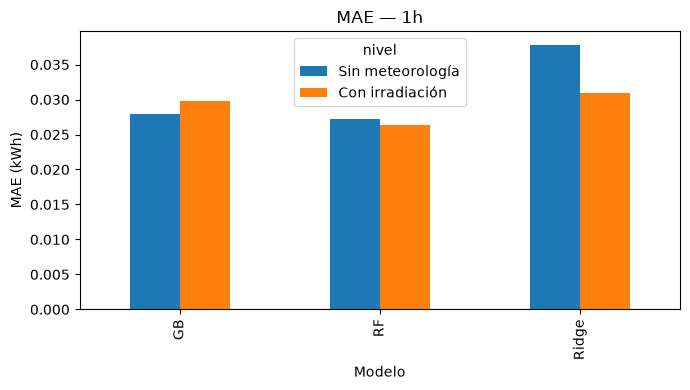

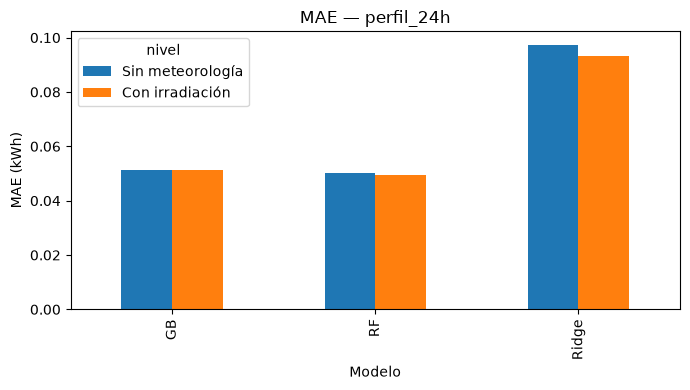

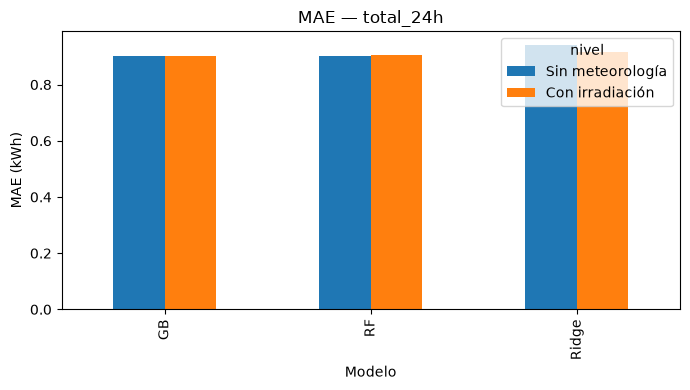

Recordatorio: el test de 2020 es conocido; CAMS no acredita disponibilidad inmediata.
GFS se evalúa retrospectivamente; la hora de inicialización aproxima su disponibilidad.


In [9]:
for nombre_objetivo in tabla.index.get_level_values("objetivo").unique():
    ax = tabla.loc[nombre_objetivo, ["Sin meteorología", "Con irradiación"]].plot.bar(
        figsize=(7, 4), title=f"MAE — {nombre_objetivo}"
    )
    ax.set_ylabel("MAE (kWh)")
    ax.set_xlabel("Modelo")
    plt.tight_layout()
    plt.show()

print("Recordatorio: el test de 2020 es conocido; CAMS no acredita disponibilidad inmediata.")
print("GFS se evalúa retrospectivamente; la hora de inicialización aproxima su disponibilidad.")

Añadir GFS no mejoró la predicción. El mejor resultado fue Random Forest con irradiación histórica, con un error medio de 0,0264 kWh.